# 03 · Baselines: soil moisture 24 h ahead (her Model 1)

Models: **persistence** (no change), **ridge linear**, **LightGBM**. Learned models predict the change, then add the current value.
Inputs grow in four steps: sensors only → + forecast → + SSURGO soil → + engineered features (v2).

Forecast inputs here are **perfect** (observed weather): an upper bound. Notebook 04 swaps in real NBM forecasts.
Splits: train 2016 to 2023 → test 2024 to 2025 (all stations), and **new station** (leave one station out).

In [1]:
# Setup: works locally (pip install -e . from the repo root) and on Google Colab
import sys, warnings
warnings.filterwarnings("ignore")
if "google.colab" in sys.modules:
    # Upload soilcast.zip to Google Drive (MyDrive) first
    from google.colab import drive
    drive.mount("/content/drive")
    !unzip -q -o /content/drive/MyDrive/soilcast.zip -d /content
    %cd /content/soilcast
    !pip install -q -e ".[gpu-trees]"
    sys.path.insert(0, "/content/soilcast/src")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from soilcast.config import PROCESSED, RAW, RESULTS
from soilcast.plotting import set_style, model_color, SERIES, MUTED
set_style()
pd.set_option("display.width", 160, "display.max_columns", 30, "display.precision", 3)
RESULTS.mkdir(exist_ok=True)

In [2]:
from soilcast.features import FEATURE_SETS, sm_valid
from soilcast.evaluate import time_split, loso_splits, sm_metrics, bootstrap_rmse_ci
from soilcast.models import fit_predict_delta, make_model
d = pd.read_parquet(PROCESSED / "features_5cm_perfect.parquet")
v = d[sm_valid(d)]
tr, te = time_split(v)
print(len(tr), "train rows,", len(te), "test rows")

148397 train rows, 41813 test rows


## Time split: all feature sets × models

In [3]:
preds, models = {"persistence": te.sm.to_numpy()}, {}
for fs, cols in FEATURE_SETS.items():
    for kind in ("linear", "gbm"):
        preds[f"{kind} | {fs}"], models[(kind, fs)] = fit_predict_delta(kind, tr[cols], tr.sm, tr.sm_t24, te[cols], te.sm)
res = sm_metrics(te.sm_t24, preds, te.sm, te.fc_precip_24h)
res.to_csv(RESULTS / "03_time_split_5cm.csv", index=False)
res

,model,RMSE_pp,MAE_pp,skill_vs_persistence,RMSE_pp_rain_events,n,n_rain_events
0,persistence,2.158,1.008,0.000,6.099,41813,3914
1,linear | sensors_24h,2.088,1.015,0.033,5.954,41813,3914
2,gbm | sensors_24h,2.054,0.975,0.048,5.821,41813,3914
3,linear | sensors+forecast,1.554,0.724,0.280,4.146,41813,3914
4,gbm | sensors+forecast,1.305,0.611,0.396,3.356,41813,3914
5,linear | sensors+forecast+soil,1.548,0.764,0.283,4.078,41813,3914
6,gbm | sensors+forecast+soil,1.151,0.559,0.467,2.749,41813,3914
7,linear | v2_engineered,1.368,0.705,0.366,3.380,41813,3914
8,gbm | v2_engineered,1.106,0.533,0.487,2.602,41813,3914


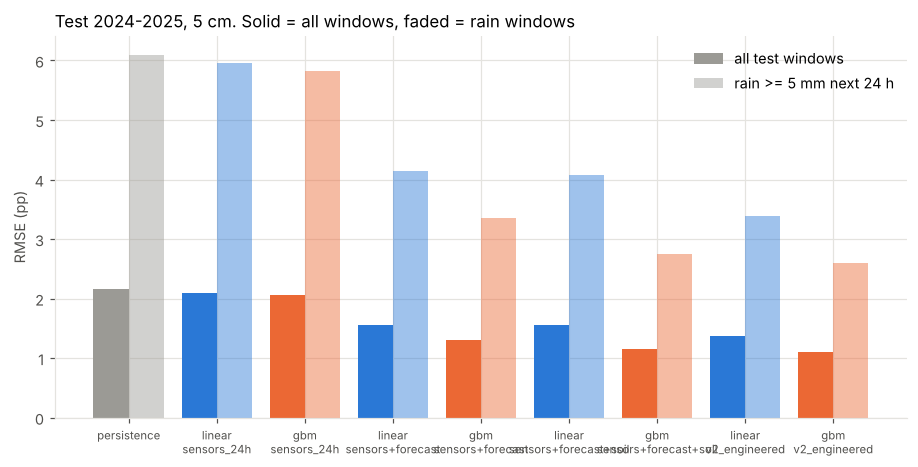

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(res))
ax.bar(x - .2, res.RMSE_pp, .4, label="all test windows", color=[model_color(m) for m in res.model])
ax.bar(x + .2, res.RMSE_pp_rain_events, .4, label="rain >= 5 mm next 24 h", color=[model_color(m) for m in res.model], alpha=.45)
ax.set_xticks(x, [m.replace(" | ", "\n") for m in res.model], fontsize=7.5)
ax.set(ylabel="RMSE (pp)", title="Test 2024-2025, 5 cm. Solid = all windows, faded = rain windows"); ax.legend();

Read the table top to bottom: almost no gain from sensors alone, a big jump once the **forecast** is added, and further gains from soil + engineered features (especially for the linear model, which can't discover interactions alone).

### Is the difference real? Bootstrap CI by station-month

In [5]:
groups = te.station + "_" + te.time_utc.dt.strftime("%Y-%m")
for name in ["persistence", "gbm | sensors+forecast+soil", "gbm | v2_engineered"]:
    lo, hi = bootstrap_rmse_ci(te.sm_t24, preds[name], groups, n=300)
    print(f"{name:32s} RMSE {100 * np.sqrt(np.mean((te.sm_t24 - preds[name]) ** 2)):.3f} pp   95% CI [{100 * lo:.3f}, {100 * hi:.3f}]")

persistence                      RMSE 2.158 pp   95% CI [1.949, 2.337]
gbm | sensors+forecast+soil      RMSE 1.151 pp   95% CI [1.044, 1.280]


gbm | v2_engineered              RMSE 1.106 pp   95% CI [1.007, 1.231]


## New station: train on 9 stations, test on the 10th (closest to deploying a new probe)

             RMSE_pp  skill_vs_persistence  RMSE_pp_rain_events
model                                                          
gbm            1.362                 0.298                3.531
linear         1.689                 0.135                4.242
persistence    2.107                 0.000                5.984


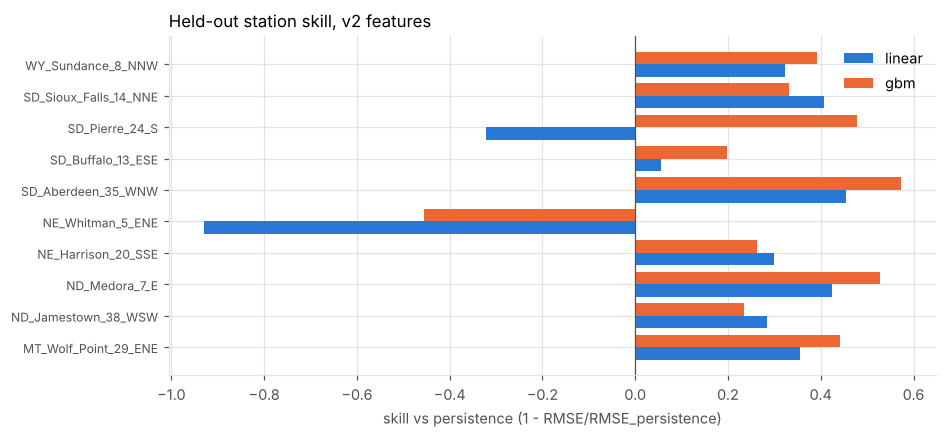

In [6]:
cols = FEATURE_SETS["v2_engineered"]
rows = []
for st, a, b in loso_splits(v):
    p = {"persistence": b.sm.to_numpy()}
    for kind in ("linear", "gbm"):
        p[kind], _ = fit_predict_delta(kind, a[cols], a.sm, a.sm_t24, b[cols], b.sm)
    r = sm_metrics(b.sm_t24, p, b.sm, b.fc_precip_24h); r.insert(0, "station", st); rows.append(r)
loso = pd.concat(rows)
loso.to_csv(RESULTS / "03_new_station_5cm.csv", index=False)
print(loso.groupby("model")[["RMSE_pp", "skill_vs_persistence", "RMSE_pp_rain_events"]].mean().round(3))
piv = loso.pivot(index="station", columns="model", values="skill_vs_persistence")
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(piv))
ax.barh(y - .2, piv["linear"], .4, label="linear", color=model_color("linear"))
ax.barh(y + .2, piv["gbm"], .4, label="gbm", color=model_color("gbm"))
ax.set_yticks(y, piv.index, fontsize=8); ax.axvline(0, color=MUTED, lw=.8)
ax.set(xlabel="skill vs persistence (1 - RMSE/RMSE_persistence)", title="Held-out station skill, v2 features"); ax.legend();

## What the GBM learned: importance and SHAP

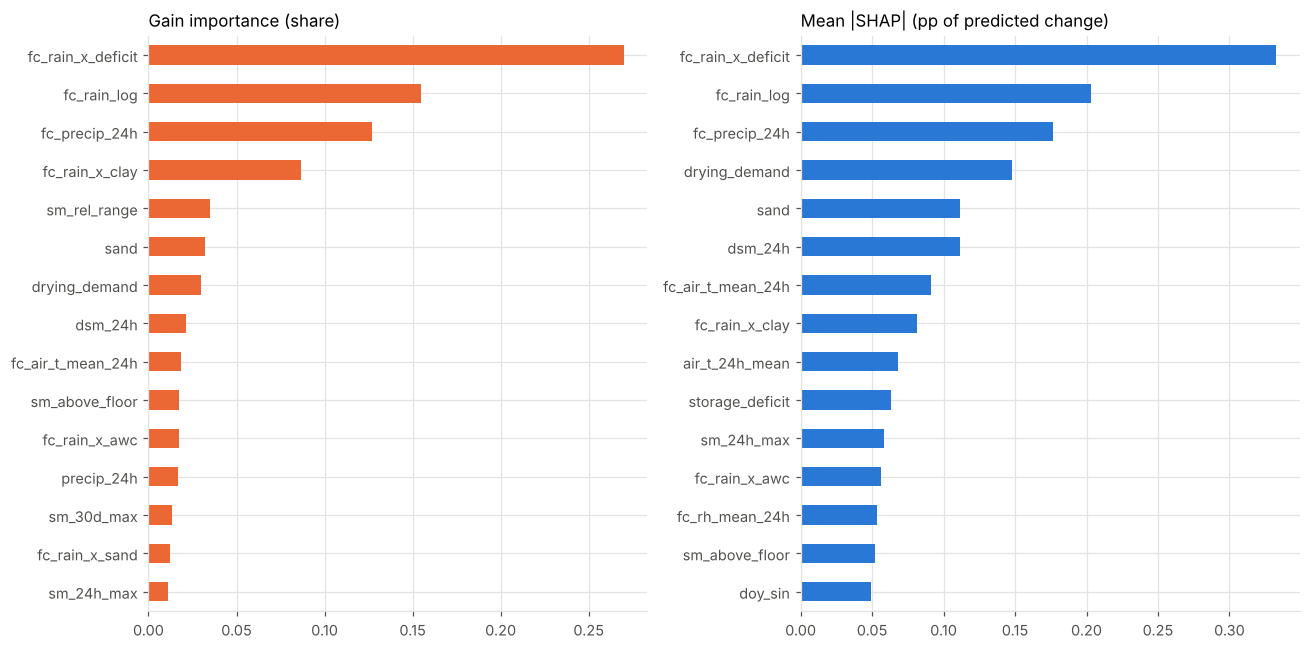

In [7]:
gbm = models[("gbm", "v2_engineered")]
imp = pd.Series(gbm.booster_.feature_importance("gain"), index=cols); imp = imp / imp.sum()
sample = te.sample(8000, random_state=0)
contrib = gbm.predict(sample[cols], pred_contrib=True)[:, :-1]   # SHAP values (LightGBM TreeSHAP)
shap = pd.DataFrame(contrib, columns=cols, index=sample.index)
mean_abs = (100 * shap.abs().mean()).sort_values()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 6))
imp.sort_values().tail(15).plot.barh(ax=a1, color=SERIES[1]); a1.set(title="Gain importance (share)")
mean_abs.tail(15).plot.barh(ax=a2, color=SERIES[0]); a2.set(title="Mean |SHAP| (pp of predicted change)")
plt.tight_layout()

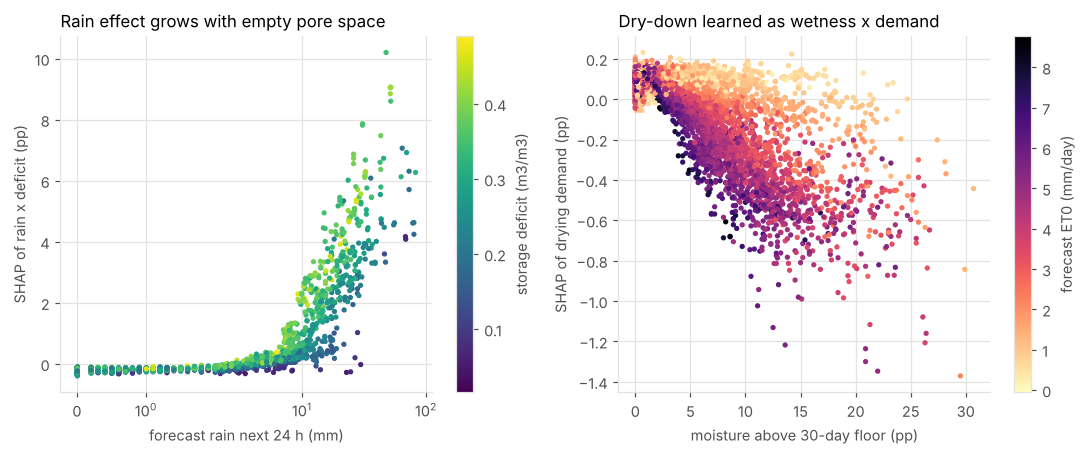

In [8]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.2))
sc = a1.scatter(sample.fc_precip_24h, 100 * shap.fc_rain_x_deficit, c=sample.porosity - sample.sm, s=6, cmap="viridis")
plt.colorbar(sc, ax=a1, label="storage deficit (m3/m3)")
a1.set(xscale="symlog", xlabel="forecast rain next 24 h (mm)", ylabel="SHAP of rain x deficit (pp)", title="Rain effect grows with empty pore space")
sc2 = a2.scatter(100 * sample.sm_above_floor, 100 * shap.drying_demand, c=sample.fc_et0_hargreaves, s=6, cmap="magma_r")
plt.colorbar(sc2, ax=a2, label="forecast ET0 (mm/day)")
a2.set(xlabel="moisture above 30-day floor (pp)", ylabel="SHAP of drying demand (pp)", title="Dry-down learned as wetness x demand");

## Where does the model still miss?

In [9]:
best = preds["gbm | v2_engineered"]
e = te.assign(err=100 * (best - te.sm_t24), perr=100 * (te.sm - te.sm_t24))
e["rain_bin"] = pd.cut(e.fc_precip_24h, [-0.1, 0.1, 1, 5, 15, 300], labels=["0", "0-1", "1-5", "5-15", "15+"])
t = e.groupby("rain_bin", observed=True).agg(n=("err", "size"), gbm_rmse=("err", lambda s: np.sqrt((s ** 2).mean())),
                                             persistence_rmse=("perr", lambda s: np.sqrt((s ** 2).mean())), gbm_bias=("err", "mean"))
t.round(3)

,n,gbm_rmse,persistence_rmse,gbm_bias
rain_bin,,,,
0,28718,0.660,1.037,0.003
0-1,3939,0.743,1.102,-0.045
1-5,3983,1.118,1.379,-0.056
5-15,2562,2.205,3.969,-0.058
15+,1324,3.254,8.914,0.556


Large rain events remain the hardest: the model under-predicts the biggest jumps (negative bias). Huber loss and per-texture tuning are levers in notebook 07.

## Example: one summer, predicted vs actual

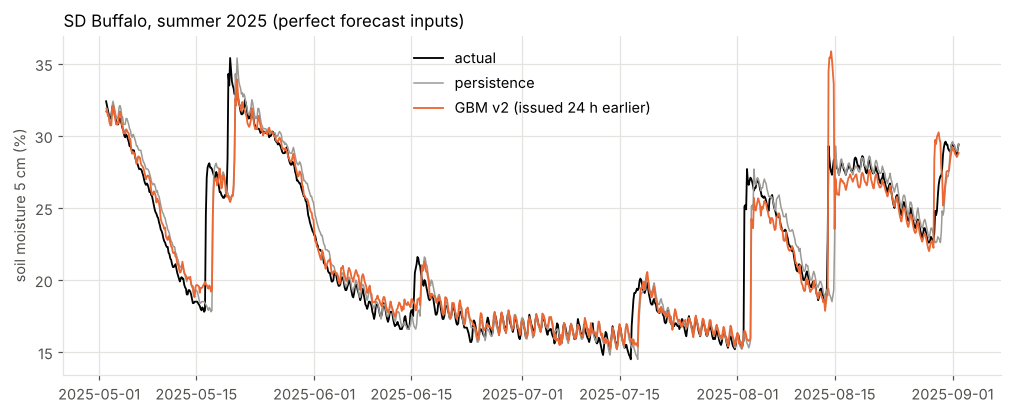

In [10]:
ex = te.assign(pred=best)
ex = ex[(ex.station == "SD_Buffalo_13_ESE") & (ex.time_utc >= "2025-05-01") & (ex.time_utc < "2025-09-01")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(ex.time_utc + pd.Timedelta("24h"), 100 * ex.sm_t24, color="black", lw=1.2, label="actual")
ax.plot(ex.time_utc + pd.Timedelta("24h"), 100 * ex.sm, color=model_color("persistence"), lw=1, label="persistence")
ax.plot(ex.time_utc + pd.Timedelta("24h"), 100 * ex.pred, color=model_color("gbm"), lw=1.2, label="GBM v2 (issued 24 h earlier)")
ax.set(ylabel="soil moisture 5 cm (%)", title="SD Buffalo, summer 2025 (perfect forecast inputs)"); ax.legend();

## Other depths (GBM v2 vs persistence)

In [11]:
rows = []
for dep in (10, 20):
    x = pd.read_parquet(PROCESSED / f"features_{dep}cm_perfect.parquet"); x = x[sm_valid(x)]
    a, b = time_split(x)
    p, _ = fit_predict_delta("gbm", a[cols], a.sm, a.sm_t24, b[cols], b.sm)
    r = sm_metrics(b.sm_t24, {"persistence": b.sm, "gbm | v2_engineered": p}, b.sm, b.fc_precip_24h); r.insert(0, "depth_cm", dep); rows.append(r)
pd.concat(rows)

,depth_cm,model,RMSE_pp,MAE_pp,skill_vs_persistence,RMSE_pp_rain_events,n,n_rain_events
0,10,persistence,1.884,0.853,0.000,5.101,43074,3934
1,10,gbm | v2_engineered,1.097,0.504,0.418,2.247,43074,3934
0,20,persistence,1.265,0.483,0.000,3.504,36874,3139
1,20,gbm | v2_engineered,0.853,0.356,0.326,1.876,36874,3139


In [12]:
# Save test predictions for comparison with the LSTM (notebook 08)
out = te[["station", "time_utc", "sm", "sm_t24", "fc_precip_24h"]].assign(
    pred_gbm_v2=preds["gbm | v2_engineered"], pred_linear_v2=preds["linear | v2_engineered"])
out.to_parquet(RESULTS / "03_test_predictions_5cm.parquet")